### **Regresión Lineal**

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay, roc_auc_score
import matplotlib.pyplot as plt
np.random.seed(42)


In [2]:
n = 900
df = pd.DataFrame({
    "comuna": np.random.choice(["Norte","Centro","Sur","Poniente"], n),
    "tipo_proyecto": np.random.choice(["Construccion","Mejoramiento"], n),
    "meses_desde_inicio": np.random.randint(2, 50, n),
    "avance_planificado_pct": np.random.uniform(20, 95, n),
    "avance_observado_pct": np.random.uniform(10, 95, n),
    "cambios_contrato": np.random.poisson(1.1, n),
    "observaciones_tecnicas": np.random.poisson(2.0, n)
})
brecha = df.avance_planificado_pct - df.avance_observado_pct
z = -2.2 + .035*brecha + .30*df.cambios_contrato + .16*df.observaciones_tecnicas
prob = 1/(1+np.exp(-z))
df["atraso_relevante"] = np.random.binomial(1, prob)
df.head()


,comuna,tipo_proyecto,meses_desde_inicio,avance_planificado_pct,avance_observado_pct,cambios_contrato,observaciones_tecnicas,atraso_relevante
0,Sur,Construccion,24,76.950825,38.880350,2,0,1
1,Poniente,Mejoramiento,22,57.533398,53.965347,1,2,0
2,Norte,Mejoramiento,20,60.677275,42.207374,1,1,0
3,Sur,Construccion,49,91.360892,10.570383,1,2,1
4,Sur,Construccion,20,83.537552,42.799333,2,3,0


In [3]:
df.shape
df.info()
df.describe(include="all")
df["atraso_relevante"].value_counts(normalize=True)
df.isna().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   comuna                  900 non-null    object 
 1   tipo_proyecto           900 non-null    object 
 2   meses_desde_inicio      900 non-null    int64  
 3   avance_planificado_pct  900 non-null    float64
 4   avance_observado_pct    900 non-null    float64
 5   cambios_contrato        900 non-null    int64  
 6   observaciones_tecnicas  900 non-null    int64  
 7   atraso_relevante        900 non-null    int64  
dtypes: float64(2), int64(4), object(2)
memory usage: 56.4+ KB


,0
comuna,0
tipo_proyecto,0
meses_desde_inicio,0
avance_planificado_pct,0
avance_observado_pct,0
cambios_contrato,0
observaciones_tecnicas,0
atraso_relevante,0


          comuna tipo_proyecto  meses_desde_inicio  avance_planificado_pct  \
count        900           900          900.000000              900.000000   
unique         4             2                 NaN                     NaN   
top     Poniente  Construccion                 NaN                     NaN   
freq         249           468                 NaN                     NaN   
mean         NaN           NaN           25.808889               56.939583   
std          NaN           NaN           13.687483               21.594455   
min          NaN           NaN            2.000000               20.014130   
25%          NaN           NaN           14.000000               37.537184   
50%          NaN           NaN           26.000000               57.122496   
75%          NaN           NaN           38.000000               75.978078   
max          NaN           NaN           49.000000               94.780862   

        avance_observado_pct  cambios_contrato  observaciones_t

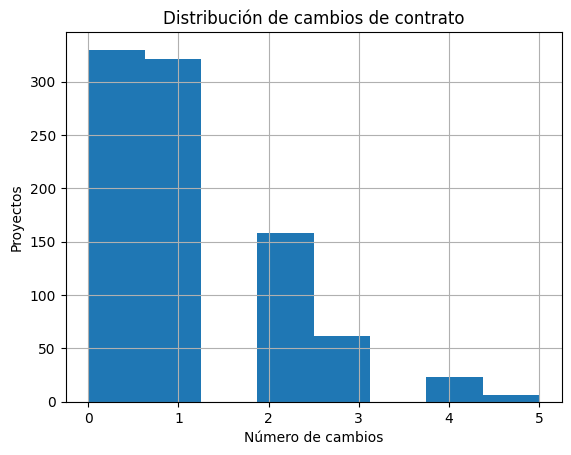

In [4]:
import matplotlib.pyplot as plt
print(df.describe(include="all"))
print(df.isna().sum())
print(df.groupby("comuna")["cambios_contrato"].agg(["mean","median","count"]))
df["cambios_contrato"].hist(bins=8)
plt.title("Distribución de cambios de contrato")
plt.xlabel("Número de cambios"); plt.ylabel("Proyectos")
plt.show()


In [5]:
rng = np.random.default_rng(42)
df["brecha_avance"] = (df["avance_planificado_pct"]
                       - df["avance_observado_pct"])
df["dias_desviacion"] = (
    8 + 0.75*df["brecha_avance"]
    + 3.5*df["cambios_contrato"]
    + 1.2*df["observaciones_tecnicas"]
    + rng.normal(0, 12, len(df))
)
print(df["dias_desviacion"].describe())


count    900.000000
mean      15.987076
std       28.071609
min      -58.388963
25%       -4.166524
50%       15.590161
75%       36.524166
max       94.477560
Name: dias_desviacion, dtype: float64


In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

cols = ["brecha_avance", "cambios_contrato", "observaciones_tecnicas", "meses_desde_inicio"]
Xl = df[cols]
yl = df["dias_desviacion"]

Xa, Xb, ya, yb = train_test_split(Xl, yl, test_size=0.25, random_state=42)

lin = LinearRegression().fit(Xa, ya)
yhat = lin.predict(Xb)

print("MAE:", round(mean_absolute_error(yb, yhat), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(yb, yhat)), 2))
print("R2:", round(r2_score(yb, yhat), 3))

# Corregido: se elimina el punto extra después de coef_
coeficientes = dict(zip(cols, lin.coef_))
print("\nCoeficientes:")
for col, coef in coeficientes.items():
    print(f"  {col}: {round(coef, 4)}")

MAE: 9.71
RMSE: 12.29
R2: 0.791

Coeficientes:
  brecha_avance: 0.7466
  cambios_contrato: 2.9361
  observaciones_tecnicas: 0.819
  meses_desde_inicio: -0.0255


### **Regresion Logistica**

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score
vars_x = ["brecha_avance","cambios_contrato",
          "observaciones_tecnicas","meses_desde_inicio"]
Xc = df[vars_x]; yc = df["atraso_relevante"]
Xa,Xb,ya,yb = train_test_split(Xc,yc,test_size=.25,
                               stratify=yc,random_state=42)
logit = LogisticRegression(max_iter=1000).fit(Xa,ya)
prob = logit.predict_proba(Xb)[:,1]
pred = (prob >= .50).astype(int)
print(classification_report(yb,pred,zero_division=0))
print("AUC:",round(roc_auc_score(yb,prob),3))


              precision    recall  f1-score   support

           0       0.80      0.92      0.85       169
           1       0.55      0.29      0.38        56

    accuracy                           0.76       225
   macro avg       0.67      0.60      0.62       225
weighted avg       0.74      0.76      0.74       225

AUC: 0.731


In [10]:
target = "atraso_relevante"
X = df.drop(columns=[target])
y = df[target]
cat_cols = ["comuna", "tipo_proyecto"]
num_cols = [c for c in X.columns if c not in cat_cols]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.25, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)


(675, 9) (225, 9)


In [11]:
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
prep = ColumnTransformer([
    ("num", num_pipe, num_cols), ("cat", cat_pipe, cat_cols)
])
model = Pipeline([
    ("prep", prep),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))
])
model.fit(X_train, y_train)
pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]


[[127  42]
 [ 22  34]]
              precision    recall  f1-score   support

           0       0.85      0.75      0.80       169
           1       0.45      0.61      0.52        56

    accuracy                           0.72       225
   macro avg       0.65      0.68      0.66       225
weighted avg       0.75      0.72      0.73       225

AUC: 0.7363693998309383


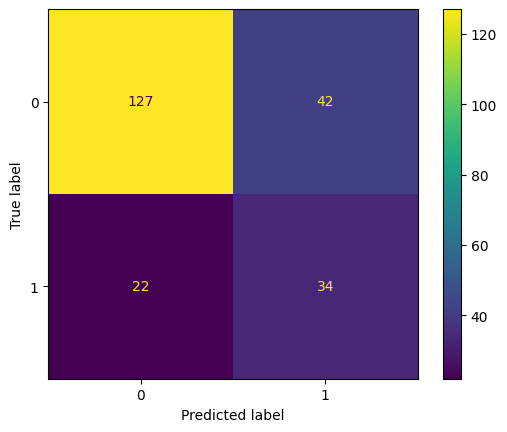

In [12]:
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))
print("AUC:", roc_auc_score(y_test, proba))
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.show()


In [13]:
alertas = X_test.copy()
alertas["prob_atraso"] = proba
alertas["real_atraso"] = y_test.values
alertas = alertas.sort_values("prob_atraso", ascending=False)
alertas.head(15)


,comuna,tipo_proyecto,meses_desde_inicio,avance_planificado_pct,avance_observado_pct,cambios_contrato,observaciones_tecnicas,brecha_avance,dias_desviacion,prob_atraso,real_atraso
678,Centro,Mejoramiento,33,94.380696,10.171574,1,5,84.209122,85.309279,0.935051,0
652,Sur,Construccion,19,81.444133,16.293589,4,3,65.150544,94.477560,0.933060,1
435,Poniente,Mejoramiento,37,72.720758,10.037636,2,5,62.683122,60.752333,0.921736,0
538,Norte,Mejoramiento,21,92.551713,11.757066,2,1,80.794647,48.064862,0.913357,1
122,Centro,Mejoramiento,27,94.661037,12.596704,3,0,82.064333,82.688210,0.904517,0
361,Norte,Construccion,41,93.379796,15.153459,1,3,78.226337,78.370479,0.899436,1
571,Sur,Mejoramiento,18,85.410178,47.002559,2,7,38.407619,51.389951,0.898528,1
39,Sur,Mejoramiento,15,59.186078,12.629700,4,3,46.556378,68.324397,0.897124,1
256,Sur,Mejoramiento,15,82.572752,10.244906,2,1,72.327846,75.663077,0.881016,1
689,Centro,Mejoramiento,43,87.770588,14.291560,1,2,73.479028,63.911986,0.845148,1


### **Segmentación**

In [14]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
cols = ["brecha_avance","cambios_contrato",
        "observaciones_tecnicas","meses_desde_inicio"]
Z = StandardScaler().fit_transform(df[cols])
for k in range(2,7):
    labels = KMeans(n_clusters=k,random_state=42,n_init=10).fit_predict(Z)
    print(k,round(silhouette_score(Z,labels),3))
km = KMeans(n_clusters=3,random_state=42,n_init=10)
df["segmento"] = km.fit_predict(Z)
print(df.groupby("segmento")[cols].median())
print(df["segmento"].value_counts())


2 0.197
3 0.201
4 0.2
5 0.202
6 0.2
          brecha_avance  cambios_contrato  observaciones_tecnicas  \
segmento                                                            
0             -0.017191               2.0                     2.0   
1             -6.884919               1.0                     2.0   
2             12.461203               0.0                     2.0   

          meses_desde_inicio  
segmento                      
0                       29.0  
1                       12.5  
2                       37.0  
segmento
2    343
1    340
0    217
Name: count, dtype: int64


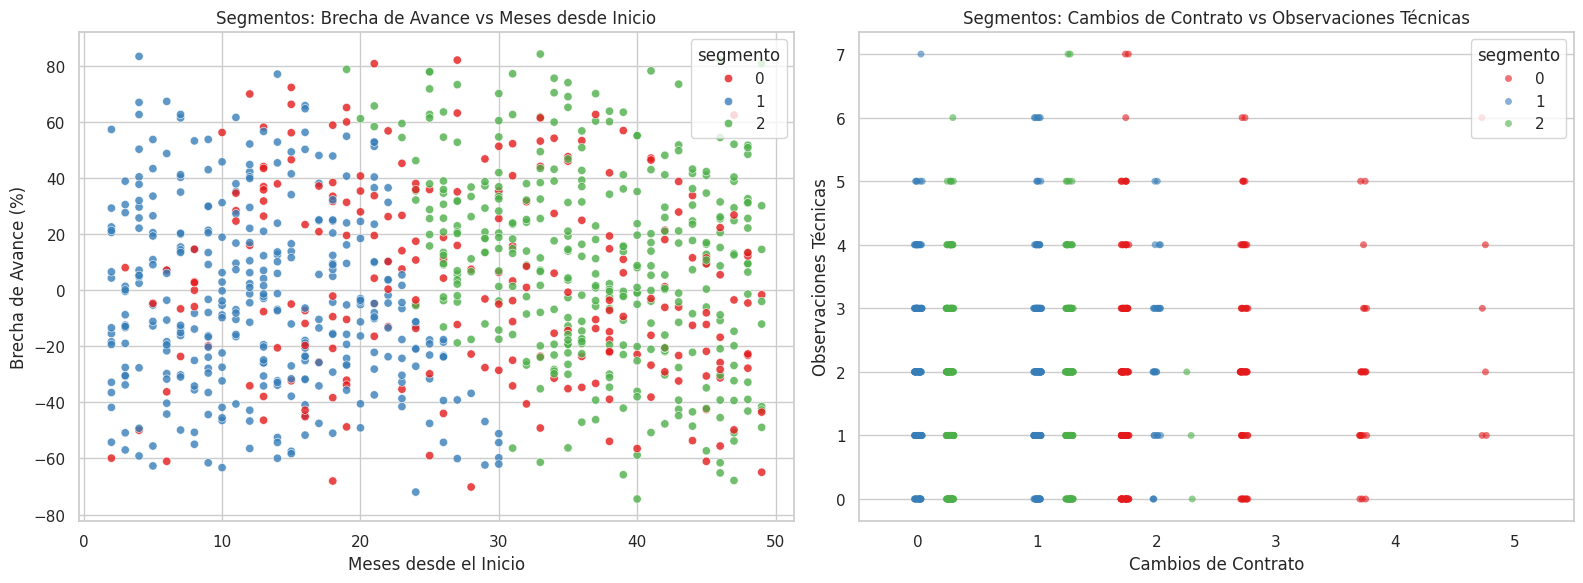

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

# Configurar el estilo visual
sns.set_theme(style="whitegrid")

# Crear una figura con dos subplots para contrastar diferentes variables
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Brecha de Avance vs Meses desde el Inicio
sns.scatterplot(
    data=df,
    x="meses_desde_inicio",
    y="brecha_avance",
    hue="segmento",
    palette="Set1",
    alpha=0.8,
    ax=axes[0]
)
axes[0].set_title("Segmentos: Brecha de Avance vs Meses desde Inicio")
axes[0].set_xlabel("Meses desde el Inicio")
axes[0].set_ylabel("Brecha de Avance (%)")

# Gráfico 2: Cambios de Contrato vs Observaciones Técnicas (con un poco de jitter para evitar superposición)
sns.stripplot(
    data=df,
    x="cambios_contrato",
    y="observaciones_tecnicas",
    hue="segmento",
    palette="Set1",
    dodge=True,
    alpha=0.6,
    ax=axes[1]
)
axes[1].set_title("Segmentos: Cambios de Contrato vs Observaciones Técnicas")
axes[1].set_xlabel("Cambios de Contrato")
axes[1].set_ylabel("Observaciones Técnicas")

plt.tight_layout()
plt.show()